# 4-02 코스닥 일일동향 — 지수·시총·종목동향·업종·상하위 종목

**질문 예시:** "코스닥 어제 하루 어땠어?", "11월 24일 코스닥 상승/하락 종목수랑 업종동향 보여줘"

CHECK 원본(`4_시황재현/02_코스닥일일동향`)은 거래소 **코스닥 일일동향 리포트**를 지수·시총·종목동향·업종·공매도·신용까지 재현했습니다.
DeepSearch에서는 이렇게 바꿉니다.

| 리포트 항목 | DeepSearch | 비고 |
|---|---|---|
| 코스닥·대중소형 지수 | `GetMarketIndexes` | 그대로 |
| 시가총액·거래대금·종목동향 | `GetStockPrices` 전 종목 하루치 | 직접 집계 (상·하한가는 ±29.5% 근사) |
| 업종동향 | 종목 업종코드(KSIC)로 **시총가중 등락률 직접 계산** | KRX 코스닥 업종지수가 없어 근사 |
| 상승·하락·거래대금 상위 종목 | 같은 스냅샷 | CHECK 리포트보다 자세히 |
| **투자자별 수급, 공매도, 신용잔고** | **없음** | DeepSearch에 데이터가 없음 (`research/data_gaps`) |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/4_market_brief/02_kosdaq_daily.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"   # 기준일 (휴장이면 직전 거래일)

In [4]:
# 업종 분류: GetStockSymbols 의 industry_id = "KRI:10" + KSIC(10차) 코드. 예) KRI:10C2612000 → C26(중분류)
KSIC_DIV = {
    "A01": "농업", "A03": "어업", "C10": "식료품", "C11": "음료", "C12": "담배", "C13": "섬유제품",
    "C14": "의복·모피", "C15": "가죽·가방·신발", "C16": "목재", "C17": "펄프·종이", "C18": "인쇄",
    "C19": "석유정제품", "C20": "화학제품", "C21": "의약품", "C22": "고무·플라스틱", "C23": "비금속광물",
    "C24": "1차금속", "C25": "금속가공", "C26": "전자부품·컴퓨터·통신장비", "C27": "의료·정밀·광학기기",
    "C28": "전기장비", "C29": "기타 기계·장비", "C30": "자동차·부품", "C31": "기타 운송장비(조선 등)",
    "C32": "가구", "C33": "기타 제품", "D35": "전기·가스", "E38": "폐기물·재생", "F41": "종합건설",
    "F42": "전문공사", "G45": "자동차 판매", "G46": "도매", "G47": "소매", "H49": "육상운송",
    "H50": "수상운송", "H51": "항공운송", "H52": "창고·운송서비스", "I55": "숙박", "J58": "출판·소프트웨어",
    "J59": "영상·오디오 제작", "J60": "방송", "J61": "통신", "J62": "IT서비스·SI", "J63": "정보서비스(포털 등)",
    "K64": "금융업", "K65": "보험", "K66": "금융서비스(증권 등)", "L68": "부동산", "M70": "연구개발(바이오 등)",
    "M71": "전문서비스", "M72": "엔지니어링", "M73": "기타 과학기술서비스", "N74": "시설관리",
    "N75": "사업지원서비스", "N76": "임대", "P85": "교육", "R90": "창작·예술", "R91": "스포츠·오락",
    "S95": "수리", "S96": "기타 개인서비스",
}
# 큰 업종 묶음 (KRX 섹터지수와 1:1은 아님 — 비교하기 쉬운 수준으로 직접 묶은 근사)
_GROUPS = {
    "반도체·전자": ["C26"], "2차전지·전기장비": ["C28"], "자동차": ["C30", "G45"], "조선·운송장비": ["C31"],
    "기계": ["C29"], "화학·정유": ["C19", "C20"], "제약·바이오": ["C21", "M70"], "의료·정밀기기": ["C27"],
    "철강·금속": ["C24", "C25"], "소재(비금속·종이·플라스틱)": ["C16", "C17", "C22", "C23"],
    "음식료·생활소비재": ["A01", "A03", "C10", "C11", "C12", "C13", "C14", "C15", "C18", "C32", "C33"],
    "건설": ["F41", "F42", "M72"], "유통·상사": ["G46", "G47"], "운송·물류": ["H49", "H50", "H51", "H52"],
    "소프트웨어·인터넷": ["J58", "J62", "J63"], "미디어·통신·엔터": ["J59", "J60", "J61", "R90", "R91"],
    "증권·금융": ["K64", "K66"], "보험": ["K65"], "유틸리티·환경": ["D35", "E38"],
    "기타 서비스": ["I55", "L68", "M71", "M73", "N74", "N75", "N76", "P85", "S95", "S96"],
}
DIV2GROUP = {d: g for g, ds_ in _GROUPS.items() for d in ds_}
FIN_HOLDING = ("금융", "신한지주")  # 이름에 들어 있으면 금융지주로 봄 (KB금융, 신한지주, 하나금융지주, 메리츠금융지주 …)


def add_sector(df):
    """industry_id·industry_name → 중분류(div, div_name)와 큰 묶음(sector). 지주회사는 따로 떼고, 금융지주는 증권·금융으로."""
    df = df.copy()
    df["div"] = df["industry_id"].str[6:9]
    df["div_name"] = df["div"].map(KSIC_DIV).fillna(df["div"])
    df["sector"] = df["div"].map(DIV2GROUP).fillna("기타 서비스")
    hold = df["industry_name"].eq("지주회사")
    fin = df["name"].str.contains("|".join(FIN_HOLDING))
    df.loc[hold & ~fin, ["sector", "div_name"]] = ["지주회사", "지주회사"]
    df.loc[hold & fin, ["sector", "div_name"]] = ["증권·금융", "금융지주"]
    return df

## 1. 코스닥 지수
지수 `change_rate`는 퍼센트, `value`는 백만원 단위입니다. 아래 그래프는 최근 약 1개월 추이입니다.

기준 거래일: 2026-11-24


,지수,종가,전일 대비,등락률(%),거래대금
0,코스닥,665.88,30.43,4.79,5.9조
1,코스닥 대형주,1583.30,87.00,5.81,3.3조
2,코스닥 중형주,733.56,30.74,4.37,1.3조
3,코스닥 소형주,1986.25,54.89,2.84,"7,969억"


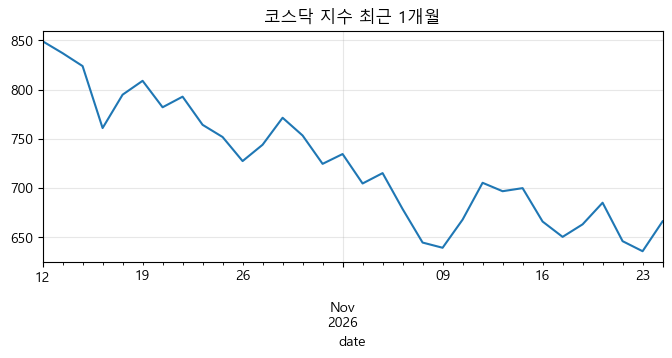

In [5]:
d = pd.Timestamp(ASOF)
ix = index_prices((d - pd.Timedelta(days=45)).date(), d.date())
DAY = ix["date"].max()
print("기준 거래일:", DAY.date())
kq = ix[ix["symbol"].str.startswith("KRX:KOSDAQ")]
t = kq[kq["date"] == DAY].set_index("symbol").loc[["KRX:KOSDAQ", "KRX:KOSDAQLC", "KRX:KOSDAQMC", "KRX:KOSDAQSC"]]
display(pd.DataFrame({"지수": t["entity_name"], "종가": t["close"].round(2), "전일 대비": t["change"].round(2),
                      "등락률(%)": t["change_rate"].round(2), "거래대금": (t["value"] * 1e6).map(krw)}).reset_index(drop=True))
ax = kq[kq["symbol"] == "KRX:KOSDAQ"].set_index("date")["close"].plot(figsize=(8, 3), title="코스닥 지수 최근 1개월")
ax.grid(alpha=.3)

## 2. 시가총액·거래·종목동향
코스닥 전 종목(우선주 포함, ETF 제외) 하루치 시세를 한 번에 받아 집계합니다. 거래가 없던 종목(거래정지 등)은 종목동향에서 뺍니다.

In [6]:
snap = all_stocks(DAY, common_only=False)
snap = snap[(snap["market"] == "KOSDAQ") & (snap["company_type_l1"] != "8") & (snap["date"] == DAY)]
traded = snap[snap["volume"] > 0]
r = traded["change_rate"]
summary = pd.Series({
    "시가총액": krw(snap["market_cap"].sum()),
    "거래대금(종목 합)": krw(snap["value"].sum()),
    "거래대금(지수)": krw(t.loc["KRX:KOSDAQ", "value"] * 1e6),
    "거래량(종목 합)": f"{snap['volume'].sum() / 1e6:,.1f}백만 주",
    "상장 종목": len(snap), "거래 종목": len(traded),
    "상승": int((r > 0).sum()), "하락": int((r < 0).sum()), "보합": int((r == 0).sum()),
    "상한가(근사, +29.5% 이상)": int(((r >= 0.295) & (r <= 0.305)).sum()),
    "하한가(근사, −29.5% 이하)": int(((r <= -0.295) & (r >= -0.305)).sum()),
    "±30% 초과(기준가 조정 의심)": int((r.abs() > 0.305).sum()),
})
display(summary.to_frame("값"))
odd = traded[traded["change_rate"].abs() > 0.305]
if len(odd):
    print("가격제한폭(±30%)을 넘은 종목 — 신규상장 첫날이거나 권리락·감자·병합 등으로 기준가가 바뀐 날일 가능성이 큽니다.")
    display(odd[["name", "close", "change_rate", "value", "date_listed"]].assign(
        change_rate=lambda x: (x.change_rate * 100).round(2), date_listed=lambda x: x.date_listed.astype(str).str[:10]))

,값
시가총액,381.4조
거래대금(종목 합),5.4조
거래대금(지수),5.9조
거래량(종목 합),409.0백만 주
상장 종목,1837
거래 종목,1750
상승,1389
하락,322
보합,39
"상한가(근사, +29.5% 이상)",10


가격제한폭(±30%)을 넘은 종목 — 신규상장 첫날이거나 권리락·감자·병합 등으로 기준가가 바뀐 날일 가능성이 큽니다.


,name,close,change_rate,value,date_listed
1157,엠비디,4230,-39.57,128363542748,2026-11-24


## 3. 업종동향 (근사)
KRX 코스닥 업종지수 대신, 종목의 표준산업분류(KSIC) 중분류별로 **시가총액 가중 평균 등락률**을 계산합니다.
종목 5개 미만인 업종은 한두 종목이 좌우하므로 뺐습니다. 큰 묶음(섹터) 기준도 함께 봅니다.

In [7]:
k = add_sector(snap[snap["symbol"].str.endswith("0") & (snap["company_type_l1"] == "1")])
k = k[k["volume"] > 0]
prev_cap = k["market_cap"] / (1 + k["change_rate"])       # 전일 시총(가중치) 근사

def wavg(g):
    w = prev_cap.loc[g.index]
    return pd.Series({"종목 수": len(g), "등락률(%)": round((g["change_rate"] * w).sum() / w.sum() * 100, 2),
                      "시가총액": krw(g["market_cap"].sum()),
                      "대표 종목": ", ".join(g.nlargest(3, "market_cap")["name"])})

div = pd.DataFrame({n: wavg(g) for n, g in k.groupby("div_name")}).T
div = div[div["종목 수"] >= 5].sort_values("등락률(%)", ascending=False)
print("[강한 업종 5]"); display(div.head(5))
print("[약한 업종 5]"); display(div.tail(5))

[강한 업종 5]


,종목 수,등락률(%),시가총액,대표 종목
자동차·부품,54,10.61,6.7조,"삼현, 한라캐스트, 성우하이텍"
전기장비,66,9.82,26.3조,"에코프로비엠, 대한광통신, 서진시스템"
지주회사,18,8.97,12.7조,"에코프로, 하림지주, 솔브레인홀딩스"
기타 기계·장비,188,8.35,76.8조,"레인보우로보틱스, 주성엔지니어링, 로보티즈"
금융업,26,6.31,2.7조,"미래에셋벤처투자, 우리기술투자, 아주IB투자"


[약한 업종 5]


,종목 수,등락률(%),시가총액,대표 종목
연구개발(바이오 등),63,-0.04,31.8조,"알테오젠, 보로노이, 리가켐바이오"
의복·모피,14,-0.26,"6,008억","나인앤컴퍼니, 더네이쳐홀딩스, 코데즈컴바인"
창작·예술,7,-0.56,"3,308억","노머스, 시공테크, 아티스트컴퍼니"
섬유제품,5,-0.71,"1,547억","셀바이오휴먼텍, 케이엠, 웰크론"
방송,6,-1.67,1.5조,"CJ ENM, 한국경제TV, KX"


In [8]:
sec = pd.DataFrame({n: wavg(g) for n, g in k.groupby("sector")}).T.sort_values("등락률(%)", ascending=False)
sec

,종목 수,등락률(%),시가총액,대표 종목
자동차,57,10.44,6.8조,"삼현, 한라캐스트, 성우하이텍"
2차전지·전기장비,66,9.82,26.3조,"에코프로비엠, 대한광통신, 서진시스템"
지주회사,18,8.97,12.7조,"에코프로, 하림지주, 솔브레인홀딩스"
기계,188,8.35,76.8조,"레인보우로보틱스, 주성엔지니어링, 로보티즈"
반도체·전자,235,5.6,51.4조,"심텍, 리노공업, 성호전자"
유통·상사,98,4.6,12.9조,"ISC, 실리콘투, 에스에이엠티"
화학·정유,91,4.42,18.9조,"원익홀딩스, 솔브레인, 동진쎄미켐"
철강·금속,71,3.99,7.5조,"에이치브이엠, 태광, 성광벤드"
증권·금융,92,3.67,5.4조,"미래에셋벤처투자, 인카금융서비스, NHN KCP"
조선·운송장비,20,3.61,3.1조,"쎄트렉아이, 현대힘스, 인화정공"


## 4. 상승률·하락률·거래대금 상위 종목
상승·하락률 상위는 시가총액 300억 원 이상 보통주만 봅니다(초소형주 쏠림 방지). 등락률이 ±30%를 넘으면 위 2절처럼 기준가 조정일일 수 있습니다.

In [9]:
c = k[k["market_cap"] >= 3e10]

def won(v):
    return krw(v) if abs(v) >= 1e8 else f"{v / 1e4:,.0f}만"

def show(df):
    return pd.DataFrame({"종목": df["name"], "업종": df["div_name"], "종가": df["close"].map("{:,.0f}".format),
                         "등락률(%)": (df["change_rate"] * 100).round(2), "거래대금": df["value"].map(won),
                         "시가총액": df["market_cap"].map(krw)}).reset_index(drop=True)
print(PRICE_NOTICE)
print("\n[상승률 상위 10]"); display(show(c.nlargest(10, "change_rate")))
print("[하락률 상위 10]"); display(show(c.nsmallest(10, "change_rate")))
print("[거래대금 상위 10]"); display(show(k.nlargest(10, "value")))

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).

[상승률 상위 10]


,종목,업종,종가,등락률(%),거래대금,시가총액
0,대성하이텍,기타 기계·장비,"5,590",30.00,56억,921억
1,모베이스전자,자동차·부품,"2,285",29.98,244억,"1,673억"
2,KH바텍,전자부품·컴퓨터·통신장비,"12,190",29.96,326억,"2,886억"
3,액트로,전자부품·컴퓨터·통신장비,"9,640",29.92,34억,923억
4,휴림로봇,기타 기계·장비,"7,430",29.90,"1,516억","8,912억"
5,아이티엠반도체,전자부품·컴퓨터·통신장비,"5,390",29.88,"3,154만","1,223억"
6,한국피아이엠,자동차·부품,"51,300",29.87,77억,"3,116억"
7,휴림에이텍,자동차·부품,"3,590",29.84,7억,359억
8,에스피지,전기장비,"90,900",24.01,785억,2.0조
9,아모텍,전자부품·컴퓨터·통신장비,"12,740",23.33,256억,"2,380억"


[하락률 상위 10]


,종목,업종,종가,등락률(%),거래대금,시가총액
0,엠비디,의료·정밀·광학기기,"4,230",-39.57,"1,284억",607억
1,아리바이오랩,연구개발(바이오 등),"3,810",-17.17,250억,"1,103억"
2,아이텍,엔지니어링,"5,800",-15.57,28억,"1,539억"
3,지슨,의료·정밀·광학기기,"5,440",-13.24,75억,599억
4,아리바이오홀딩스,전기장비,"2,220",-12.60,63억,"1,178억"
5,시선AI,출판·소프트웨어,"2,540",-9.61,25억,361억
6,큐리언트,연구개발(바이오 등),"11,400",-9.52,141억,"4,279억"
7,압타바이오,연구개발(바이오 등),"3,970",-9.46,6억,"1,115억"
8,미스터블루,정보서비스(포털 등),"1,909",-8.66,8억,317억
9,티에프이,전자부품·컴퓨터·통신장비,"60,100",-7.11,193억,"7,421억"


[거래대금 상위 10]


,종목,업종,종가,등락률(%),거래대금,시가총액
0,원익홀딩스,화학제품,"31,350",-2.18,"3,446억",2.4조
1,로보티즈,기타 기계·장비,"294,000",19.51,"2,090억",4.3조
2,주성엔지니어링,기타 기계·장비,"149,800",5.72,"2,026억",7.0조
3,알테오젠,연구개발(바이오 등),"159,700",-5.22,"1,713억",11.1조
4,휴림로봇,기타 기계·장비,"7,430",29.90,"1,516억","8,912억"
5,레인보우로보틱스,기타 기계·장비,"472,000",17.41,"1,406억",9.2조
6,엠비디,의료·정밀·광학기기,"4,230",-39.57,"1,284억",607억
7,빅웨이브로보틱스,출판·소프트웨어,"21,500",-0.69,"1,207억","2,211억"
8,대한광통신,전기장비,"14,860",7.06,"1,106억",2.3조
9,금양그린파워,전문공사,"10,930",13.62,"1,104억","1,325억"


## 5. 한 줄 요약
투자자별 수급·공매도·신용잔고는 DeepSearch에 데이터가 없어 넣지 못했습니다(`research/data_gaps`).

In [10]:
print(f"{DAY.date()} 코스닥은 {t.loc['KRX:KOSDAQ','close']:,.2f}({t.loc['KRX:KOSDAQ','change_rate']:+.2f}%)로 마감했습니다. "
      f"상승 {summary['상승']:,}·하락 {summary['하락']:,}·보합 {summary['보합']:,}종목, 상한가(근사) {summary['상한가(근사, +29.5% 이상)']}·하한가(근사) {summary['하한가(근사, −29.5% 이하)']}종목. "
      f"가장 강한 업종은 {div.index[0]}({div.iloc[0]['등락률(%)']:+.2f}%), 가장 약한 업종은 {div.index[-1]}({div.iloc[-1]['등락률(%)']:+.2f}%)입니다.")

2026-11-24 코스닥은 665.88(+4.79%)로 마감했습니다. 상승 1,389·하락 322·보합 39종목, 상한가(근사) 10·하한가(근사) 0종목. 가장 강한 업종은 자동차·부품(+10.61%), 가장 약한 업종은 방송(-1.67%)입니다.
